### ☑️ Overfitting & Underfitting
과적합과 과소적합이란 아래 예시로 설명이된다.

- 학생 A : 문제집의 내용도 이해 못해서 연습문제도 틀리고 시험도 틀리는 상태<br/>
    &rightarrow; **과소적합**(Underfitting)

- 학생 B : 문제집의 답을 전부 외워서 연습문제는 100점이지만, 숫자만 바뀐 시험은 다 틀리는 상태<br/>
    &rightarrow; **과적합**(Overfitting)

- 학생 C : 문제를 푸는 원리를 이해해서 연습문제와 시험 모두 잘 푸는 상태<br/>
    &rightarrow; **일반화**(Generalization)가 잘된 상태

#### 1️⃣ 과소적합 (Underfitting)
과소적합은 다시 말하자면 모델이 너무 단순하거나 충분히 학습하지 못해 데이터의 패턴을 제대로 파악하지 못한상태이다.

과소적합을 일반적으로 Train 성능도 낮고, Validation 성능도 낮고, 모델이 데이터의 중요한 패턴을 놓치는 특징이 있다.

#### 2️⃣ 과적합 (Overfitting)
과적합은 모델이 학습 데이터에 지나치게 맞춰진 상태이다.

훈련 데이터의 노이즈나 세부 패턴까지 학습해 새로운 데이터에 대한 예측력이 떨어지는 현상이다.

과적합은 일반적으로 Train성능은 매우 높지만 Validation 성능은 상대적으로 낮다.

In [ ]:
# 과소적합과 과적합 확인해보기
# DecisionTreeClassifier 사용
from sklearn.datasets import load_breast_cancer
from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import accuracy_score

# 데이터 불러오기
cancer = load_breast_cancer(as_frame=True)

# Feature, Target 구분
X = cancer.data
y = cancer.target

# 이번에는 과적합 관찰을 위해 Train과 Validation으로 분리
X_train, X_val, y_train, y_val = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

# 모델 생성 (깊이 1)
# 깊이가 1, 2, 5, 10... 점점 커질수록 Train에 대한 데이터 학습은 많아져서 Train 정확도는 매우 높아지지만
# Validation이나 Test에 대한 정확도까지 높아지지는 않는다.
model = DecisionTreeClassifier(
    max_depth=1,
    random_state=42
)

# 모델 학습
model.fit(X_train, y_train)

# 예측값 확인
train_pred = model.predict(X_train)
val_pred = model.predict(X_val)

train_acc = accuracy_score(y_train, train_pred)
val_acc = accuracy_score(y_val, val_pred)

print("Train Accuracy:", train_acc)
print("Validation Accuracy:", val_acc)

Train Accuracy: 0.9230769230769231
Validation Accuracy: 0.9210526315789473


In [4]:
# 만약 max_depth=None이라면
# Train은 완벽하게 학습된다.
model = DecisionTreeClassifier(
    max_depth=None,
    random_state=42
)

# 모델 학습
model.fit(X_train, y_train)

# 예측값 확인
train_pred = model.predict(X_train)
val_pred = model.predict(X_val)

train_acc = accuracy_score(y_train, train_pred)
val_acc = accuracy_score(y_val, val_pred)

print("Train Accuracy:", train_acc)
print("Validation Accuracy:", val_acc)

Train Accuracy: 1.0
Validation Accuracy: 0.9122807017543859


In [ ]:
# max_depth에 따른 정확도 비교해보가
import pandas as pd

results = []

for depth in [1, 2, 3, 5, 10, None]:
    model = DecisionTreeClassifier(
        max_depth=depth,
        random_state=42
    )

    model.fit(X_train, y_train)

    # model.socre()는
    # model.predict()와 accuracy_score()를 합친 코드라고 생각하면 된다.
    train_acc = model.score(X_train, y_train)
    val_acc = model.score(X_val, y_val)

    results.append({
        "max_depth": str(depth),
        "train_accuracy": train_acc,
        "validation_accuracy": val_acc,
        "gap": train_acc - val_acc
    })

# 아래 결과 데이터 프레임엥서 gap의 차이가 클수록 과적합을 의심할 수 있다.
# 하지만 과적합이 작더라고 무조건 좋은 모델은 아니다. 과소적합일수도 있기 때문이다.
result_df = pd.DataFrame(results)
result_df

,max_depth,train_accuracy,validation_accuracy,gap
0,1,0.923077,0.921053,0.002024
1,2,0.958242,0.894737,0.063505
2,3,0.975824,0.938596,0.037228
3,5,0.993407,0.921053,0.072354
4,10,1.000000,0.912281,0.087719
5,None,1.000000,0.912281,0.087719


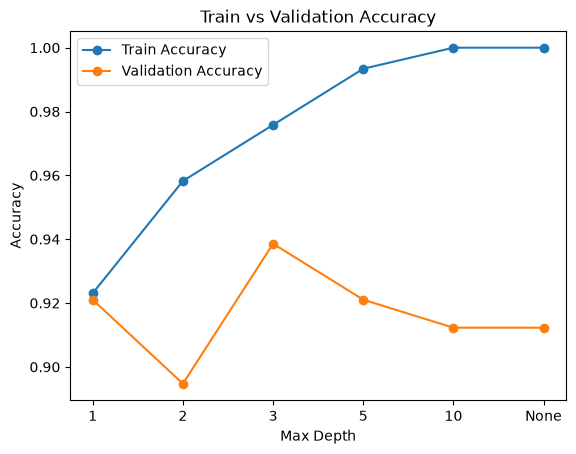

In [ ]:
# 결과 시각화 해보기
import matplotlib.pyplot as plt

plt.plot(
    result_df["max_depth"],
    result_df["train_accuracy"],
    marker="o",
    label="Train Accuracy"
)

plt.plot(
    result_df["max_depth"],
    result_df["validation_accuracy"],
    marker="o",
    label="Validation Accuracy"
)

plt.xlabel("Max Depth")
plt.ylabel("Accuracy")
plt.title("Train vs Validation Accuracy")
plt.legend()
plt.show()